# GrapeLeafNet — Dual-Track Feature Fusion Experiment
**Paper:** GrapeLeafNet: A Dual-Track Feature Fusion Network With Inception-ResNet and Shuffle-Transformer for Accurate Grape Leaf Disease Identification (IEEE Access, 2024)  
**Authors:** R. Karthik et al.  
**Framework:** PyTorch  
**Dataset:** PlantVillage — Grape Leaf (4 classes)

| Scenario | Augmentation |
|---|---|
| Baseline | None (Resize + Normalize) |
| Augmented | Rotation + Shear + Width Shift + H/V Flip + Brightness + Gaussian Blur |

In [1]:
# BLOCK 0: Install dependencies
!pip install -q torchinfo openpyxl Pillow

In [2]:
# BLOCK 1: Imports
import os
import math
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchinfo import summary as torch_summary
from sklearn.metrics import (
    accuracy_score, f1_score, recall_score,
    confusion_matrix, ConfusionMatrixDisplay,
    classification_report
)

torch.manual_seed(42)
torch.cuda.manual_seed_all(42)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
n_gpus = torch.cuda.device_count()
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
print(f'Device: {DEVICE} | GPUs available: {n_gpus}')


In [3]:
# BLOCK 2: Config
import glob as _glob

def _find_dataset(base='/kaggle/input'):
    for train_path in sorted(_glob.glob(f'{base}/**/train', recursive=True)):
        bp = os.path.dirname(train_path)
        if (os.path.isdir(os.path.join(bp, 'val')) and
                os.path.isdir(os.path.join(bp, 'test'))):
            return bp
    return None

DATASET_PATH = _find_dataset()
if DATASET_PATH is None:
    raise FileNotFoundError(
        'Cannot auto-detect dataset. Attach a dataset with train/val/test folders.'
    )
print(f'[Auto] Dataset: {DATASET_PATH}')

TRAIN_DIR      = os.path.join(DATASET_PATH, 'train')
VAL_DIR        = os.path.join(DATASET_PATH, 'val')
TEST_DIR       = os.path.join(DATASET_PATH, 'test')
PAPER_CITATION = 'Karthik et al. (2024) - IEEE Access'
MODEL_NAME     = 'GrapeLeafNet'

IMG_SIZE     = (256, 256)
BATCH_SIZE   = 32
EPOCHS       = 120
LR           = 1e-4
WEIGHT_DECAY = 1e-4
DROPOUT      = 0.5
OUTPUT_DIR   = '/kaggle/working'
os.makedirs(OUTPUT_DIR, exist_ok=True)

MEAN = [0.485, 0.456, 0.406]
STD  = [0.229, 0.224, 0.225]

# Auto-detect classes tu TRAIN_DIR
CLASS_NAMES = sorted([
    d for d in os.listdir(TRAIN_DIR)
    if os.path.isdir(os.path.join(TRAIN_DIR, d))
])
NUM_CLASSES = len(CLASS_NAMES)
print(f'Classes ({NUM_CLASSES}): {CLASS_NAMES}')

BASELINE_LC_PATH = f'{OUTPUT_DIR}/{MODEL_NAME}_NoAug_LC.png'
BASELINE_CM_PATH = f'{OUTPUT_DIR}/{MODEL_NAME}_NoAug_CM.png'
AUG_LC_PATH      = f'{OUTPUT_DIR}/{MODEL_NAME}_Aug_LC.png'
AUG_CM_PATH      = f'{OUTPUT_DIR}/{MODEL_NAME}_Aug_CM.png'


In [4]:
# BLOCK 3: Dataset Exploration
splits = {'Train': TRAIN_DIR, 'Val': VAL_DIR, 'Test': TEST_DIR}
stats  = {}
for split, path in splits.items():
    counts = {}
    if os.path.isdir(path):
        for cls in sorted(os.listdir(path)):
            cls_path = os.path.join(path, cls)
            if os.path.isdir(cls_path):
                counts[cls] = len(os.listdir(cls_path))
    stats[split] = counts
    print(f'{split}: {sum(counts.values())} images — {counts}')

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (split, counts) in zip(axes, stats.items()):
    ax.bar(counts.keys(), counts.values(), color=['#2196F3','#4CAF50','#FF9800','#E91E63'])
    ax.set_title(f'{split} Set Distribution', fontsize=13, fontweight='bold')
    ax.set_xlabel('Class'); ax.set_ylabel('Count')
    ax.tick_params(axis='x', rotation=30)
    for i, v in enumerate(counts.values()):
        ax.text(i, v + 1, str(v), ha='center', fontsize=10)
plt.suptitle('GrapeLeafNet — Dataset Statistics', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/dataset_statistics.png', dpi=300, bbox_inches='tight')
plt.show()
# Class imbalance auto-detection (Rule 11)
from sklearn.utils.class_weight import compute_class_weight
train_counts_list = list(stats['Train'].values())
max_count = max(train_counts_list)
min_count = min(train_counts_list)
imbalance_ratio = max_count / min_count
print(f'\nImbalance ratio (max/min): {imbalance_ratio:.2f}')
if imbalance_ratio >= 1.5:
    all_labels_flat = []
    for i, cnt in enumerate(train_counts_list):
        all_labels_flat.extend([i] * cnt)
    all_labels_flat = np.array(all_labels_flat)
    cw = compute_class_weight('balanced', classes=np.unique(all_labels_flat), y=all_labels_flat)
    CLASS_WEIGHTS = torch.tensor(cw, dtype=torch.float32)
    print(f'[Imbalanced] Using class weights: {CLASS_WEIGHTS}')
else:
    CLASS_WEIGHTS = None
    print('[Balanced] No class weighting applied.')

# Class imbalance auto-detection (Rule 11)
from sklearn.utils.class_weight import compute_class_weight
train_counts_list = list(stats['Train'].values())
max_count = max(train_counts_list)
min_count = min(train_counts_list)
imbalance_ratio = max_count / min_count
print(f'\nImbalance ratio (max/min): {imbalance_ratio:.2f}')
if imbalance_ratio >= 1.5:
    all_labels_flat = []
    for i, cnt in enumerate(train_counts_list):
        all_labels_flat.extend([i] * cnt)
    all_labels_flat = np.array(all_labels_flat)
    cw = compute_class_weight('balanced', classes=np.unique(all_labels_flat), y=all_labels_flat)
    CLASS_WEIGHTS = torch.tensor(cw, dtype=torch.float32)
    print(f'[Imbalanced] Using class weights: {CLASS_WEIGHTS}')
else:
    CLASS_WEIGHTS = None
    print('[Balanced] No class weighting applied.')


In [5]:
# BLOCK 4A: Inception-ResNet Block
class InceptionResNetBlock(nn.Module):
    """Parallel multi-scale conv branches + 1x1 bottleneck + residual add."""
    def __init__(self, in_channels, out_channels):
        super().__init__()
        mid = out_channels // 4

        # Branch 1: 1x1 → 3x3 → 3x3
        self.branch1 = nn.Sequential(
            nn.Conv2d(in_channels, mid, 1), nn.BatchNorm2d(mid), nn.ReLU(inplace=True),
            nn.Conv2d(mid, mid, 3, padding=1), nn.BatchNorm2d(mid), nn.ReLU(inplace=True),
            nn.Conv2d(mid, mid, 3, padding=1), nn.BatchNorm2d(mid), nn.ReLU(inplace=True),
        )
        # Branch 2: 1x1 → 3x3
        self.branch2 = nn.Sequential(
            nn.Conv2d(in_channels, mid, 1), nn.BatchNorm2d(mid), nn.ReLU(inplace=True),
            nn.Conv2d(mid, mid, 3, padding=1), nn.BatchNorm2d(mid), nn.ReLU(inplace=True),
        )
        # Branch 3: 1x1
        self.branch3 = nn.Sequential(
            nn.Conv2d(in_channels, mid, 1), nn.BatchNorm2d(mid), nn.ReLU(inplace=True),
        )
        # Branch 4: 1x1
        self.branch4 = nn.Sequential(
            nn.Conv2d(in_channels, mid, 1), nn.BatchNorm2d(mid), nn.ReLU(inplace=True),
        )
        # Bottleneck to reduce concatenated channels back to out_channels
        self.bottleneck = nn.Sequential(
            nn.Conv2d(out_channels, out_channels, 1),
            nn.BatchNorm2d(out_channels),
        )
        # Residual projection if in_channels != out_channels
        self.residual = (
            nn.Sequential(nn.Conv2d(in_channels, out_channels, 1), nn.BatchNorm2d(out_channels))
            if in_channels != out_channels else nn.Identity()
        )
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        b1 = self.branch1(x)
        b2 = self.branch2(x)
        b3 = self.branch3(x)
        b4 = self.branch4(x)
        out = self.bottleneck(torch.cat([b1, b2, b3, b4], dim=1))
        return self.relu(out + self.residual(x))

In [7]:
# BLOCK 4B: CBAM — Channel + Spatial Attention
class ChannelAttention(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Linear(channels, channels // reduction, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(channels // reduction, channels, bias=False),
        )

    def forward(self, x):
        B, C, H, W = x.shape
        avg = self.mlp(x.mean(dim=[2,3]))
        mx  = self.mlp(x.amax(dim=[2,3]))
        scale = torch.sigmoid(avg + mx).view(B, C, 1, 1)
        return x * scale


class SpatialAttention(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, kernel_size=7, padding=3, bias=False)

    def forward(self, x):
        avg_map = x.mean(dim=1, keepdim=True)
        max_map = x.amax(dim=1, keepdim=True)
        scale = torch.sigmoid(self.conv(torch.cat([avg_map, max_map], dim=1)))
        return x * scale


class CBAM(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        self.ca = ChannelAttention(channels, reduction)
        self.sa = SpatialAttention()

    def forward(self, x):
        return self.sa(self.ca(x))

In [9]:
# BLOCK 4C: Coordinate Attention
class CoordinateAttention(nn.Module):
    def __init__(self, channels, reduction=32):
        super().__init__()
        mid = max(8, channels // reduction)
        self.conv1  = nn.Conv2d(channels, mid, 1)
        self.bn1    = nn.BatchNorm2d(mid)
        self.relu   = nn.ReLU(inplace=True)
        self.conv_h = nn.Conv2d(mid, channels, 1)
        self.conv_w = nn.Conv2d(mid, channels, 1)

    def forward(self, x):
        B, C, H, W = x.shape
        h_pool = x.mean(dim=3, keepdim=True)           # B,C,H,1
        w_pool = x.mean(dim=2, keepdim=True)           # B,C,1,W
        combined = torch.cat([h_pool, w_pool.permute(0,1,3,2)], dim=2)  # B,C,H+W,1
        combined = self.relu(self.bn1(self.conv1(combined)))
        h_feat   = combined[:, :, :H, :]
        w_feat   = combined[:, :, H:, :].permute(0,1,3,2)
        attn_h   = torch.sigmoid(self.conv_h(h_feat))
        attn_w   = torch.sigmoid(self.conv_w(w_feat))
        return x * attn_h * attn_w

In [11]:
# BLOCK 4D: Shuffle Transformer
def window_partition(x, window_size):
    B, H, W, C = x.shape
    x = x.view(B, H // window_size, window_size, W // window_size, window_size, C)
    return x.permute(0, 1, 3, 2, 4, 5).contiguous().view(-1, window_size, window_size, C)

def window_reverse(windows, window_size, H, W):
    B = int(windows.shape[0] / (H * W / window_size / window_size))
    x = windows.view(B, H // window_size, W // window_size, window_size, window_size, -1)
    return x.permute(0, 1, 3, 2, 4, 5).contiguous().view(B, H, W, -1)

class WindowAttention(nn.Module):
    def __init__(self, dim, window_size, num_heads):
        super().__init__()
        self.num_heads   = num_heads
        self.window_size = window_size
        head_dim         = dim // num_heads
        self.scale       = head_dim ** -0.5
        self.qkv         = nn.Linear(dim, dim * 3)
        self.proj        = nn.Linear(dim, dim)

    def forward(self, x):
        B_, N, C = x.shape
        qkv = self.qkv(x).reshape(B_, N, 3, self.num_heads, C // self.num_heads).permute(2,0,3,1,4)
        q, k, v = qkv.unbind(0)
        attn = (q @ k.transpose(-2,-1)) * self.scale
        attn = attn.softmax(dim=-1)
        x    = (attn @ v).transpose(1, 2).reshape(B_, N, C)
        return self.proj(x)

class MLP(nn.Module):
    def __init__(self, dim, mlp_ratio=4):
        super().__init__()
        hidden = int(dim * mlp_ratio)
        self.net = nn.Sequential(
            nn.Linear(dim, hidden), nn.GELU(),
            nn.Linear(hidden, dim),
        )
    def forward(self, x): return self.net(x)

class NeighborWindowConnection(nn.Module):
    """Local depthwise conv to connect neighboring windows."""
    def __init__(self, dim):
        super().__init__()
        self.dw = nn.Conv2d(dim, dim, kernel_size=3, padding=1, groups=dim)
        self.pw = nn.Conv2d(dim, dim, kernel_size=1)
        self.bn = nn.BatchNorm2d(dim)

    def forward(self, x, H, W):
        B, L, C = x.shape
        x2d = x.transpose(1,2).view(B, C, H, W)
        x2d = self.bn(self.pw(self.dw(x2d)))
        return x2d.view(B, C, L).transpose(1,2)

class ShuffleTransformerBlock(nn.Module):
    def __init__(self, dim, num_heads, window_size=8, mlp_ratio=4):
        super().__init__()
        self.window_size = window_size
        self.norm1  = nn.LayerNorm(dim)
        self.wmsa   = WindowAttention(dim, window_size, num_heads)
        self.norm2  = nn.LayerNorm(dim)
        self.mlp1   = MLP(dim, mlp_ratio)
        self.norm3  = nn.LayerNorm(dim)
        self.swmsa  = WindowAttention(dim, window_size, num_heads)
        self.nwc    = NeighborWindowConnection(dim)
        self.norm4  = nn.LayerNorm(dim)
        self.mlp2   = MLP(dim, mlp_ratio)

    def _pad_and_partition(self, x, H, W):
        ws = self.window_size
        pad_h = (ws - H % ws) % ws
        pad_w = (ws - W % ws) % ws
        if pad_h > 0 or pad_w > 0:
            x = x.view(-1, H, W, x.shape[-1])
            x = F.pad(x.permute(0,3,1,2), (0, pad_w, 0, pad_h)).permute(0,2,3,1)
        else:
            x = x.view(-1, H, W, x.shape[-1])
        Hp, Wp = H + pad_h, W + pad_w
        windows = window_partition(x, ws)
        windows = windows.view(-1, ws*ws, x.shape[-1])
        return windows, Hp, Wp

    def _merge_windows(self, windows, Hp, Wp, H, W):
        ws = self.window_size
        C  = windows.shape[-1]
        windows = windows.view(-1, ws, ws, C)
        x = window_reverse(windows, ws, Hp, Wp)
        if Hp > H or Wp > W:
            x = x[:, :H, :W, :].contiguous()
        return x.view(-1, H*W, C)

    def _channel_shuffle(self, x, groups=2):
        B, N, C = x.shape
        x = x.view(B, N, groups, C // groups).permute(0,1,3,2).contiguous()
        return x.view(B, N, C)

    def forward(self, x, H, W):
        # WMSA
        shortcut = x
        windows, Hp, Wp = self._pad_and_partition(self.norm1(x), H, W)
        windows = self.wmsa(windows)
        x = self._merge_windows(windows, Hp, Wp, H, W) + shortcut
        x = x + self.mlp1(self.norm2(x))

        # Shuffle-WMSA
        shortcut = x
        windows, Hp, Wp = self._pad_and_partition(self._channel_shuffle(self.norm3(x)), H, W)
        windows = self.swmsa(windows)
        x = self._merge_windows(windows, Hp, Wp, H, W) + shortcut

        # NWC + MLP2
        x = x + self.nwc(x, H, W)
        x = x + self.mlp2(self.norm4(x))
        return x

class PatchEmbed(nn.Module):
    def __init__(self, in_ch=3, embed_dim=32, patch_size=4):
        super().__init__()
        self.proj = nn.Conv2d(in_ch, embed_dim, kernel_size=patch_size, stride=patch_size)
        self.norm = nn.LayerNorm(embed_dim)

    def forward(self, x):
        x = self.proj(x)
        B, C, H, W = x.shape
        x = x.flatten(2).transpose(1, 2)
        return self.norm(x), H, W

class PatchMerging(nn.Module):
    """Token Merging: halves spatial resolution, doubles channels."""
    def __init__(self, dim):
        super().__init__()
        self.norm      = nn.LayerNorm(4 * dim)
        self.reduction = nn.Linear(4 * dim, 2 * dim, bias=False)

    def forward(self, x, H, W):
        B, L, C = x.shape
        x  = x.view(B, H, W, C)
        x0 = x[:, 0::2, 0::2, :]
        x1 = x[:, 1::2, 0::2, :]
        x2 = x[:, 0::2, 1::2, :]
        x3 = x[:, 1::2, 1::2, :]
        x  = torch.cat([x0, x1, x2, x3], dim=-1).view(B, -1, 4*C)
        return self.reduction(self.norm(x)), H // 2, W // 2

class ShuffleTransformerTrack(nn.Module):
    """4-stage Shuffle Transformer with Token Merging.
    
    FIX: nn.ModuleList cannot hold None — merges stored separately
    as a real ModuleList; _do_merge is a plain bool list.
    """
    def __init__(self, img_size=256, in_ch=3, embed_dim=32,
                 depths=[1,1,1,1], num_heads=[1,2,4,8],
                 window_size=8, mlp_ratio=4):
        super().__init__()
        self.patch_embed = PatchEmbed(in_ch, embed_dim, patch_size=4)
        self.stages      = nn.ModuleList()
        self.merges      = nn.ModuleList()  # only real PatchMerging modules
        self._do_merge   = []               # plain bool list, not registered
        dim = embed_dim
        for i, (d, h) in enumerate(zip(depths, num_heads)):
            self.stages.append(nn.ModuleList([
                ShuffleTransformerBlock(dim, h, window_size, mlp_ratio)
                for _ in range(d)
            ]))
            if i < len(depths) - 1:
                self.merges.append(PatchMerging(dim))
                self._do_merge.append(True)
                dim *= 2
            else:
                self._do_merge.append(False)
        self.out_channels = dim

    def forward(self, x):
        x, H, W   = self.patch_embed(x)
        merge_idx = 0
        for i, stage in enumerate(self.stages):
            for blk in stage:
                x = blk(x, H, W)
            if self._do_merge[i]:
                x, H, W = self.merges[merge_idx](x, H, W)
                merge_idx += 1
        B, L, C = x.shape
        return x.transpose(1,2).view(B, C, H, W)

In [12]:
# BLOCK 4E: GrapeLeafNet — Full Architecture
class CNNStage(nn.Module):
    def __init__(self, in_ch, conv_ch, out_ch):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, conv_ch, 3, padding=1),
            nn.BatchNorm2d(conv_ch), nn.ReLU(inplace=True),
        )
        self.ir   = InceptionResNetBlock(conv_ch, out_ch)
        self.pool = nn.MaxPool2d(2, 2)
        self.drop = nn.Dropout2d(0.1)

    def forward(self, x):
        return self.drop(self.pool(self.ir(self.conv(x))))


class GrapeLeafNet(nn.Module):
    def __init__(self, num_classes=4, dropout=0.5):
        super().__init__()

        # ── Track 1: CNN + Inception-ResNet + CBAM ──────────────────────────
        # Initial Conv + Pool: 256→128
        self.init_conv = nn.Sequential(
            nn.Conv2d(3, 8, 3, padding=1), nn.BatchNorm2d(8), nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),                                   # 128x128x8
        )
        # Stages: 128→64→32→16→8
        self.stage1 = CNNStage(8,  16,  16)   # 64x64
        self.stage2 = CNNStage(16, 32,  32)   # 32x32
        self.stage3 = CNNStage(32, 64,  64)   # 16x16
        self.stage4 = CNNStage(64, 128, 128)  # 8x8

        self.cnn_proj = nn.Sequential(
            nn.Conv2d(128, 256, 3, padding=1),
            nn.BatchNorm2d(256), nn.ReLU(inplace=True),           # 8x8x256
        )
        self.cbam = CBAM(256)

        # ── Track 2: Shuffle Transformer ────────────────────────────────────
        self.shuffle_track = ShuffleTransformerTrack(
            img_size=256, in_ch=3, embed_dim=32,
            depths=[1,1,1,1], num_heads=[1,2,4,8],
            window_size=8, mlp_ratio=4,
        )  # output: 8x8x256

        # ── Fusion ───────────────────────────────────────────────────────────
        self.fusion_conv = nn.Sequential(
            nn.Conv2d(512, 512, 3, padding=1),
            nn.BatchNorm2d(512), nn.ReLU(inplace=True),
        )
        self.coord_attn = CoordinateAttention(512)

        # ── Classifier ───────────────────────────────────────────────────────
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(512, 128), nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        # Track 1
        t1 = self.init_conv(x)
        t1 = self.stage1(t1)
        t1 = self.stage2(t1)
        t1 = self.stage3(t1)
        t1 = self.stage4(t1)
        t1 = self.cbam(self.cnn_proj(t1))          # B,256,8,8

        # Track 2
        t2 = self.shuffle_track(x)                 # B,256,8,8

        # Fusion
        fused = torch.cat([t1, t2], dim=1)         # B,512,8,8
        fused = self.coord_attn(self.fusion_conv(fused))

        return self.classifier(fused)

In [13]:
# BLOCK 5: Training & Evaluation Functions
def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss    = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * imgs.size(0)
        correct    += (outputs.argmax(1) == labels).sum().item()
        total      += imgs.size(0)
    return total_loss / total, correct / total


@torch.no_grad()
def validate(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
        outputs = model(imgs)
        loss    = criterion(outputs, labels)
        total_loss += loss.item() * imgs.size(0)
        correct    += (outputs.argmax(1) == labels).sum().item()
        total      += imgs.size(0)
    return total_loss / total, correct / total


@torch.no_grad()
def collect_preds(model, loader):
    model.eval()
    all_preds, all_labels = [], []
    for imgs, labels in loader:
        imgs = imgs.to(DEVICE)
        preds = model(imgs).argmax(1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())
    return np.array(all_labels), np.array(all_preds)


def run_training(model, train_loader, val_loader, epochs, lr, wd,
                 checkpoint_path, class_weights=None):
    weight_tensor = class_weights.to(DEVICE) if class_weights is not None else None
    criterion = nn.CrossEntropyLoss(weight=weight_tensor)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    history   = {'train_loss':[], 'val_loss':[], 'train_acc':[], 'val_acc':[]}
    best_val_acc = 0.0
    for epoch in range(1, epochs + 1):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer, criterion)
        va_loss, va_acc = validate(model, val_loader, criterion)
        history['train_loss'].append(tr_loss)
        history['val_loss'].append(va_loss)
        history['train_acc'].append(tr_acc)
        history['val_acc'].append(va_acc)
        if va_acc > best_val_acc:
            best_val_acc = va_acc
            torch.save(model.state_dict(), checkpoint_path)
        if epoch % 10 == 0 or epoch == 1:
            print(f'Epoch {epoch:3d}/{epochs} | '
                  f'Loss: {tr_loss:.4f}/{va_loss:.4f} | '
                  f'Acc: {tr_acc:.4f}/{va_acc:.4f}')
    # Reload best checkpoint before evaluation
    model.load_state_dict(torch.load(checkpoint_path, map_location=DEVICE))
    print(f'[Checkpoint] Best val_acc={best_val_acc:.4f} — reloaded from {checkpoint_path}')
    return history


def save_confusion_matrix(y_true, y_pred, title, path):
    cm   = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
    fig, ax = plt.subplots(figsize=(10, 8))
    disp.plot(cmap='Blues', ax=ax, xticks_rotation=30, colorbar=True)
    ax.set_title(title, fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(path, dpi=300, bbox_inches='tight')
    plt.show()


def save_learning_curve(history, title, path):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    epochs = range(1, len(history['train_acc']) + 1)
    axes[0].plot(epochs, history['train_acc'], label='Train')
    axes[0].plot(epochs, history['val_acc'],   label='Val')
    axes[0].set_title('Accuracy'); axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Accuracy')
    axes[0].legend()
    axes[1].plot(epochs, history['train_loss'], label='Train')
    axes[1].plot(epochs, history['val_loss'],   label='Val')
    axes[1].set_title('Loss'); axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Loss')
    axes[1].legend()
    plt.suptitle(title, fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(path, dpi=300, bbox_inches='tight')
    plt.show()


---
## SCENARIO 1: NO AUGMENTATION (BASELINE)

In [14]:
# BLOCK 6: Transforms & DataLoaders — Scenario 1 (No-Aug)
transform_noaug = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])

train_ds_s1 = datasets.ImageFolder(TRAIN_DIR, transform=transform_noaug)
val_ds_s1   = datasets.ImageFolder(VAL_DIR,   transform=transform_noaug)
test_ds_s1  = datasets.ImageFolder(TEST_DIR,  transform=transform_noaug)

# Sync CLASS_NAMES with ImageFolder index order
CLASS_NAMES = train_ds_s1.classes
NUM_CLASSES  = len(CLASS_NAMES)

train_loader_s1 = DataLoader(train_ds_s1, batch_size=BATCH_SIZE, shuffle=True,  num_workers=4, pin_memory=True)
val_loader_s1   = DataLoader(val_ds_s1,   batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)
test_loader_s1  = DataLoader(test_ds_s1,  batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)

print(f'Train: {len(train_ds_s1)} | Val: {len(val_ds_s1)} | Test: {len(test_ds_s1)}')
print(f'Classes: {CLASS_NAMES}')


In [15]:
# BLOCK 7: Build Model & Summary — Scenario 1
model_s1 = GrapeLeafNet(num_classes=NUM_CLASSES, dropout=DROPOUT).to(DEVICE)

torch_summary(
    model_s1,
    input_size=(1, 3, *IMG_SIZE),
    col_names=['output_size', 'num_params', 'trainable'],
    verbose=1,
)
total_params = sum(p.numel() for p in model_s1.parameters() if p.requires_grad)
print(f'\nTotal Trainable Parameters: {total_params:,}')


In [16]:
# BLOCK 8: Train — Scenario 1 (No-Aug)
print('=== SCENARIO 1: Training without Augmentation ===')
history_s1 = run_training(
    model_s1, train_loader_s1, val_loader_s1,
    epochs=EPOCHS, lr=LR, wd=WEIGHT_DECAY,
    checkpoint_path=f'{OUTPUT_DIR}/best_model_s1.pth',
    class_weights=CLASS_WEIGHTS,
)


In [17]:
# BLOCK 9: Classification Report — Scenario 1
y_true_s1, y_pred_s1 = collect_preds(model_s1, test_loader_s1)

acc_s1    = accuracy_score(y_true_s1, y_pred_s1)
f1_s1     = f1_score(y_true_s1, y_pred_s1, average='macro')
recall_s1 = recall_score(y_true_s1, y_pred_s1, average='macro')

print('=' * 60)
print(f'  SCENARIO 1 (No-Aug) — RESULTS')
print('=' * 60)
print(f'  Total Parameters : {total_params:,}')
print(f'  Accuracy         : {acc_s1:.4f}')
print(f'  F1-Score (Macro) : {f1_s1:.4f}')
print(f'  Recall (Macro)   : {recall_s1:.4f}')
print('=' * 60)
print('\nClassification Report (per class):')
print(classification_report(y_true_s1, y_pred_s1, target_names=CLASS_NAMES, digits=4))

baseline_metrics = {
    'model_name'   : MODEL_NAME,
    'accuracy'     : acc_s1,
    'f1_macro'     : f1_s1,
    'recall_macro' : recall_s1,
    'total_params' : total_params,
}
BASELINE_LEARNING_CURVE_PATH  = BASELINE_LC_PATH
BASELINE_CONFUSION_MATRIX_PATH = BASELINE_CM_PATH

  SCENARIO 1 (No-Aug) — RESULTS
  Total Parameters : 5,308,035
  Accuracy         : 0.7828
  F1-Score (Macro) : 0.7872
  Recall (Macro)   : 0.7883

Classification Report (per class):
                     precision    recall  f1-score   support

        anthracnose     1.0000    1.0000    1.0000        62
            healthy     0.6765    0.8846    0.7667        78
          leaf_curl     0.8571    0.5676    0.6829        74
          leaf_spot     0.6329    0.6579    0.6452        76
nutrient_deficiency     0.8519    0.8313    0.8415        83

           accuracy                         0.7828       373
          macro avg     0.8037    0.7883    0.7872       373
       weighted avg     0.7962    0.7828    0.7807       373



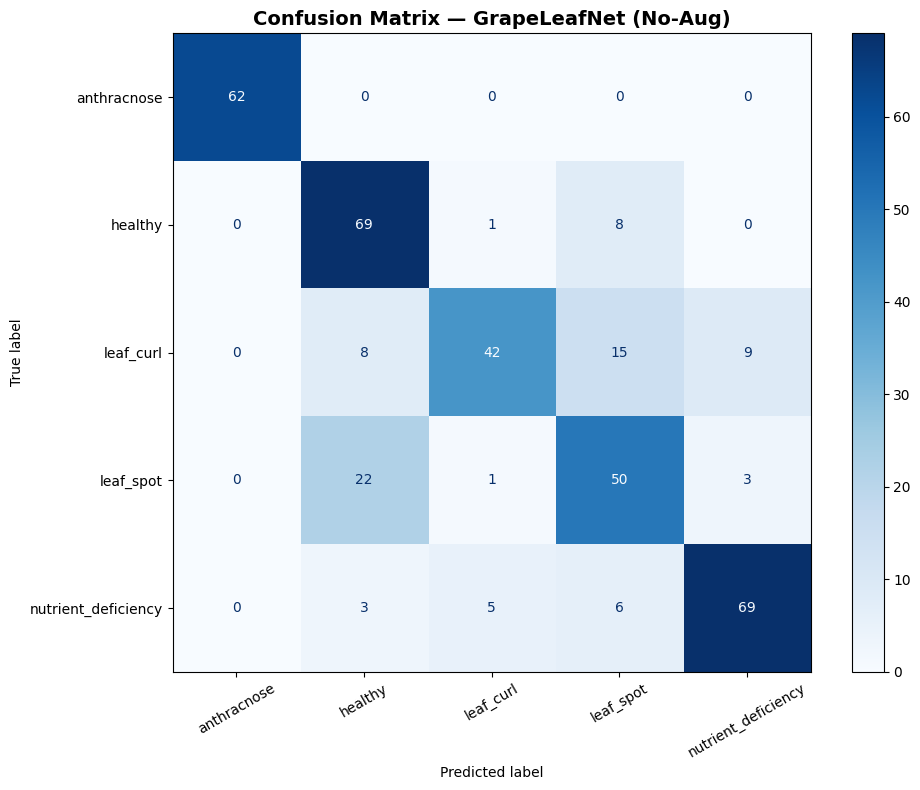

In [18]:
# BLOCK 10: Confusion Matrix — Scenario 1
save_confusion_matrix(
    y_true_s1, y_pred_s1,
    title=f'Confusion Matrix — {MODEL_NAME} (No-Aug)',
    path=BASELINE_CM_PATH
)

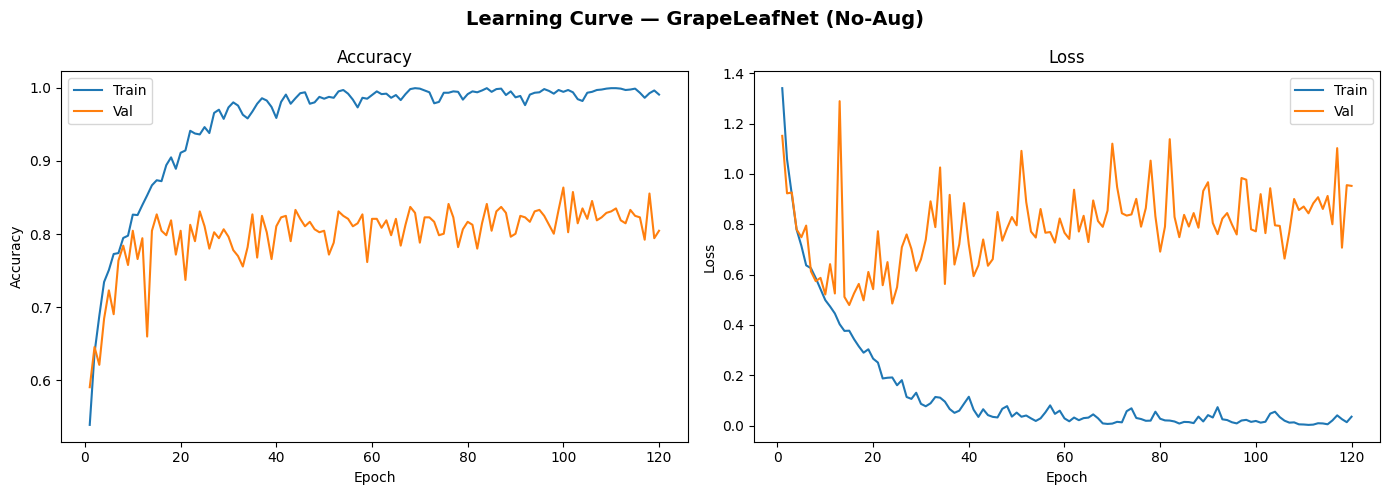

In [19]:
# BLOCK 11: Learning Curve — Scenario 1
save_learning_curve(
    history_s1,
    title=f'Learning Curve — {MODEL_NAME} (No-Aug)',
    path=BASELINE_LC_PATH
)

---
## SCENARIO 2: WITH AUGMENTATION

In [22]:
# BLOCK 12: Transforms & DataLoaders — Scenario 2 (Aug)
# 4 core augmentation techniques as required:
# Rotation, Zoom/Scale (RandomResizedCrop), Horizontal Flip, ColorJitter
# + Paper-specific: Shear, Width Shift, Vertical Flip, Gaussian Blur
transform_aug = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.RandomRotation(degrees=40),                       # Rotation 0-40°
    transforms.RandomAffine(degrees=0, shear=0.2, translate=(0.2, 0)),  # Shear + Width shift
    transforms.RandomHorizontalFlip(p=0.5),                     # Horizontal Flip
    transforms.RandomVerticalFlip(p=0.5),                       # Vertical Flip
    transforms.ColorJitter(brightness=(0.5, 1.5)),              # Brightness 0.5-1.5
    transforms.GaussianBlur(kernel_size=3, sigma=(0.01, 0.8)),  # Gaussian Blur sigma 0-0.8
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])

train_ds_s2 = datasets.ImageFolder(TRAIN_DIR, transform=transform_aug)
val_ds_s2   = datasets.ImageFolder(VAL_DIR,   transform=transform_noaug)  # val không aug
test_ds_s2  = datasets.ImageFolder(TEST_DIR,  transform=transform_noaug)

train_loader_s2 = DataLoader(train_ds_s2, batch_size=BATCH_SIZE, shuffle=True,  num_workers=4, pin_memory=True)
val_loader_s2   = DataLoader(val_ds_s2,   batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)
test_loader_s2  = DataLoader(test_ds_s2,  batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)

print(f'Train (Aug): {len(train_ds_s2)} | Val: {len(val_ds_s2)} | Test: {len(test_ds_s2)}')

In [23]:
# BLOCK 13: Re-initialize Model — Scenario 2 (prevent data leakage)
torch.cuda.empty_cache()
print('[GPU] Cache cleared between scenarios.')

model_s2 = GrapeLeafNet(num_classes=NUM_CLASSES, dropout=DROPOUT).to(DEVICE)

total_params_s2 = sum(p.numel() for p in model_s2.parameters() if p.requires_grad)
print(f'Model re-initialized. Total Trainable Parameters: {total_params_s2:,}')


In [24]:
# BLOCK 14: Train — Scenario 2 (Aug)
print('=== SCENARIO 2: Training WITH Augmentation ===')
history_s2 = run_training(
    model_s2, train_loader_s2, val_loader_s2,
    epochs=EPOCHS, lr=LR, wd=WEIGHT_DECAY,
    checkpoint_path=f'{OUTPUT_DIR}/best_model_s2.pth',
    class_weights=CLASS_WEIGHTS,
)


In [25]:
# BLOCK 15: Classification Report — Scenario 2
y_true_s2, y_pred_s2 = collect_preds(model_s2, test_loader_s2)

acc_s2    = accuracy_score(y_true_s2, y_pred_s2)
f1_s2     = f1_score(y_true_s2, y_pred_s2, average='macro')
recall_s2 = recall_score(y_true_s2, y_pred_s2, average='macro')

print('=' * 60)
print(f'  SCENARIO 2 (Aug) — RESULTS')
print('=' * 60)
print(f'  Total Parameters : {total_params_s2:,}')
print(f'  Accuracy         : {acc_s2:.4f}')
print(f'  F1-Score (Macro) : {f1_s2:.4f}')
print(f'  Recall (Macro)   : {recall_s2:.4f}')
print('=' * 60)
print('\nClassification Report (per class):')
print(classification_report(y_true_s2, y_pred_s2, target_names=CLASS_NAMES, digits=4))

aug_metrics = {
    'model_name'   : MODEL_NAME,
    'accuracy'     : acc_s2,
    'f1_macro'     : f1_s2,
    'recall_macro' : recall_s2,
    'total_params' : total_params_s2,
}
AUG_LEARNING_CURVE_PATH   = AUG_LC_PATH
AUG_CONFUSION_MATRIX_PATH = AUG_CM_PATH

  SCENARIO 2 (Aug) — RESULTS
  Total Parameters : 5,308,035
  Accuracy         : 0.9571
  F1-Score (Macro) : 0.9587
  Recall (Macro)   : 0.9582

Classification Report (per class):
                     precision    recall  f1-score   support

        anthracnose     1.0000    1.0000    1.0000        62
            healthy     0.9167    0.9872    0.9506        78
          leaf_curl     0.9577    0.9189    0.9379        74
          leaf_spot     0.9859    0.9211    0.9524        76
nutrient_deficiency     0.9412    0.9639    0.9524        83

           accuracy                         0.9571       373
          macro avg     0.9603    0.9582    0.9587       373
       weighted avg     0.9582    0.9571    0.9571       373



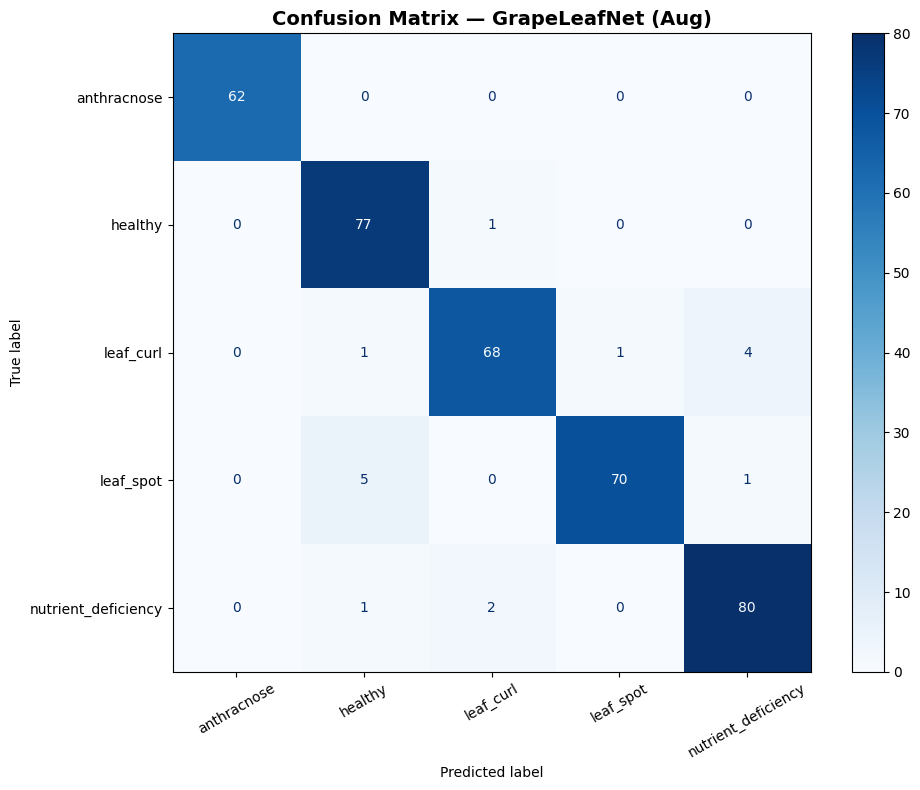

In [26]:
# BLOCK 16: Confusion Matrix — Scenario 2
save_confusion_matrix(
    y_true_s2, y_pred_s2,
    title=f'Confusion Matrix — {MODEL_NAME} (Aug)',
    path=AUG_CM_PATH
)

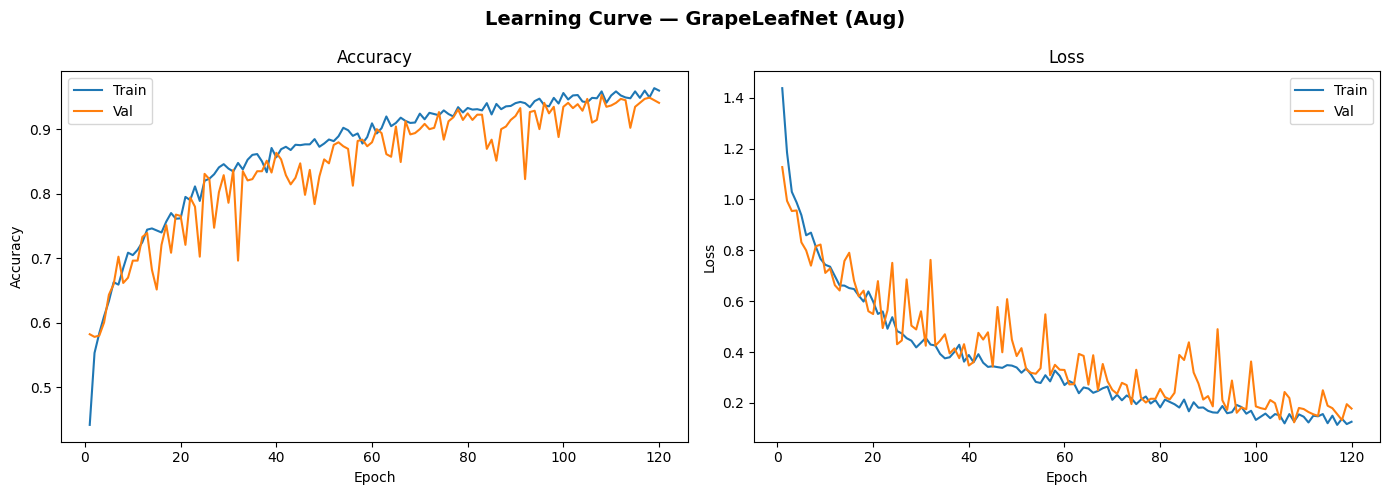

In [27]:
# BLOCK 17: Learning Curve — Scenario 2
save_learning_curve(
    history_s2,
    title=f'Learning Curve — {MODEL_NAME} (Aug)',
    path=AUG_LC_PATH
)

---
## EXCEL EXPORT

In [28]:
# BLOCK 18: Install Excel dependencies
!pip install -q openpyxl Pillow

In [29]:
# BLOCK 19: Export results_summary.xlsx
import openpyxl
from openpyxl import Workbook
from openpyxl.styles import Font, Alignment, PatternFill, Border, Side
from openpyxl.drawing.image import Image as XLImage
from openpyxl.utils import get_column_letter
import os

EXCEL_OUTPUT_PATH = f'{OUTPUT_DIR}/results_summary.xlsx'
HEADERS    = ['STT', 'Tên Model', 'Accuracy', 'F1-score', 'Recall',
              'Learning Curve', 'Confusion Matrix', 'Parameters']
COL_WIDTHS = [6, 40, 12, 12, 12, 40, 40, 18]

def style_header_row(ws):
    fill   = PatternFill('solid', fgColor='1F4E79')
    font   = Font(bold=True, color='FFFFFF', size=11)
    border = Border(
        bottom=Side(style='medium', color='FFFFFF'),
        right=Side(style='thin',   color='FFFFFF'),
    )
    for col, header in enumerate(HEADERS, start=1):
        cell = ws.cell(row=1, column=col, value=header)
        cell.fill, cell.font, cell.border = fill, font, border
        cell.alignment = Alignment(horizontal='center', vertical='center', wrap_text=True)

def write_result_row(ws, row_num, stt, metrics, lc_path, cm_path):
    data = [
        stt,
        f"{metrics['model_name']} ({PAPER_CITATION})",
        round(metrics['accuracy'], 4),
        round(metrics['f1_macro'], 4),
        round(metrics['recall_macro'], 4),
        '', '',
        f"{metrics['total_params']:,}",
    ]
    for col, val in enumerate(data, start=1):
        cell = ws.cell(row=row_num, column=col, value=val)
        cell.alignment = Alignment(horizontal='center', vertical='center', wrap_text=True)
    ws.row_dimensions[row_num].height = 200
    if os.path.exists(lc_path):
        img = XLImage(lc_path); img.width, img.height = 280, 190
        ws.add_image(img, f'F{row_num}')
    if os.path.exists(cm_path):
        img = XLImage(cm_path); img.width, img.height = 280, 190
        ws.add_image(img, f'G{row_num}')

def build_sheet(wb, sheet_name, metrics, lc_path, cm_path):
    ws = wb.create_sheet(title=sheet_name)
    for col, width in enumerate(COL_WIDTHS, start=1):
        ws.column_dimensions[get_column_letter(col)].width = width
    ws.row_dimensions[1].height = 30
    style_header_row(ws)
    write_result_row(ws, 2, 1, metrics, lc_path, cm_path)

wb = Workbook()
wb.remove(wb.active)
build_sheet(wb, 'Baseline',  baseline_metrics, BASELINE_LC_PATH, BASELINE_CM_PATH)
build_sheet(wb, 'Augmented', aug_metrics,      AUG_LC_PATH,      AUG_CM_PATH)
wb.save(EXCEL_OUTPUT_PATH)

print(f'[Excel] Saved: {EXCEL_OUTPUT_PATH}')
print(f'  Baseline  → Acc={baseline_metrics["accuracy"]:.4f} | F1={baseline_metrics["f1_macro"]:.4f} | Recall={baseline_metrics["recall_macro"]:.4f} | Params={baseline_metrics["total_params"]:,}')
print(f'  Augmented → Acc={aug_metrics["accuracy"]:.4f}      | F1={aug_metrics["f1_macro"]:.4f}      | Recall={aug_metrics["recall_macro"]:.4f}      | Params={aug_metrics["total_params"]:,}')

[Excel] Saved: /kaggle/working/results_summary.xlsx
  Baseline  → Acc=0.7828 | F1=0.7872 | Recall=0.7883 | Params=5,308,035
  Augmented → Acc=0.9571      | F1=0.9587      | Recall=0.9582      | Params=5,308,035
